In [1]:
# Imports necesarios para el análisis
import zipfile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pearsonr, probplot
from IPython.display import display

sns.set(style="whitegrid")

In [2]:
# Cargar el dataset desde el archivo zip
zip_path = r"C:\Users\marle\Downloads\amz_uk_price_prediction_dataset.csv (2).zip"

with zipfile.ZipFile(zip_path) as z:
    with z.open("amz_uk_price_prediction_dataset.csv") as f:
        df = pd.read_csv(f, encoding="latin1", low_memory=False)

df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories
# Objective: Understand the relationship between product categories and their best-seller status.

# 1) Crosstab Analysis:
#    - Create a crosstab between the product `category` and the `isBestSeller` status.
#    - Are there categories where being a best-seller is more prevalent?
#      Hint: calculate the proportion of best-sellers for each category and sort descending.

# 2) Statistical Tests:
#    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
#    - Compute Cramér's V to understand the strength of association between best-seller status and category.

# 3) Visualizations:
#    - Visualize the relationship using a stacked bar chart of `category` vs `isBestSeller`. 

In [4]:
#1. Crosstab Analysis

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
proportions = (
    pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
    .rename(columns={0: 'not_best_seller', 1: 'best_seller'})
)

proportions['best_seller_pct'] = proportions['best_seller'] * 100

# Ordenar y redondear a 2 decimales
proportions = proportions.sort_values(by='best_seller_pct', ascending=False)
proportions = proportions.round(2)

display(proportions)



isBestSeller,not_best_seller,best_seller,best_seller_pct
category,,,
Grocery,0.94,0.06,5.81
Smart Home Security & Lighting,0.94,0.06,5.77
Health & Personal Care,0.94,0.06,5.77
Mobile Phone Accessories,0.96,0.04,4.25
Power & Hand Tools,0.96,0.04,3.53
...,...,...,...
Bedding Collections,1.00,0.00,0.00
CPUs,1.00,0.00,0.00
"CD, Disc & Tape Players",1.00,0.00,0.00


In [6]:
#In grocery, smart home and health & personal care categories more than 5% of products are best-sellers.

In [7]:
# 2) Statistical Tests:

contingency_table = pd.crosstab(df['category'], df['isBestSeller'])
contingency_table

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
#test chi-cuadrado

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

#p < 0.05 → existe relación significativa entre categoría y best-seller.
#p ≥ 0.05 → no hay evidencia de relación.

Chi-square statistic: 36540.20270061387
Degrees of freedom: 295
p-value: 0.0


In [9]:
#Therefore, best-seller status is not independent of product category.
#The distribution of best-sellers varies significantly across categories, implying that some categories contain disproportionately more best-selling products than others.

In [10]:
#Cramer's V calculation
n = contingency_table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_table.shape) - 1)))
print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


In [11]:
#However, Cramér’s V = 0.122 suggests that the strength of this association is weak.
#This means that although category does influence the likelihood of a product becoming a best-seller, the effect size is small.
#Other variables beyond category likely play a more important role in determining best-seller performance.

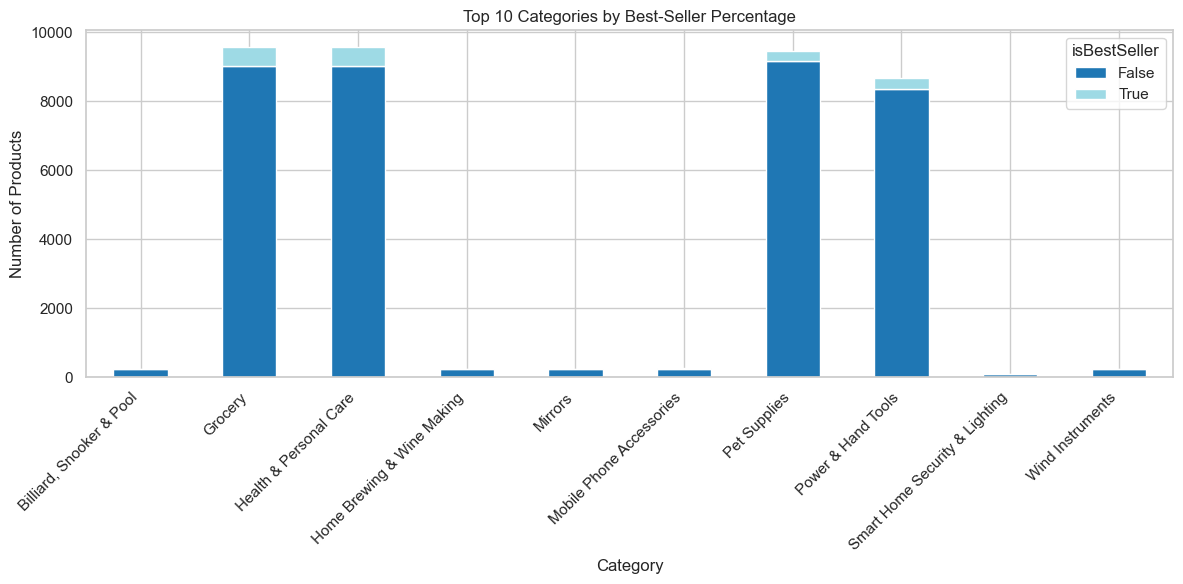

In [12]:
#3. Visualizations

# Seleccionar las top 10 categorías con mayor % de best-sellers
top10 = proportions.sort_values('best_seller_pct', ascending=False).head(10)
top10

contingency_top10 = pd.crosstab(
    df[df['category'].isin(top10.index)]['category'],
    df['isBestSeller']
)

contingency_top10.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    colormap='tab20'
)

plt.title("Top 10 Categories by Best-Seller Percentage")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
# Objective: Investigate how different product categories influence product prices.
# Preliminary Step: Remove outliers in product prices using the IQR method.
#    - Products below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are outliers.

# 1) Violin Plots:
#    - Visualize the distribution of `price` across product `categories`.
#    - Filter out the top 20 categories based on count for better visualization.
#    - Which category tends to have the highest median price? (No top filter here.)

# 2) Bar Charts:
#    - Compare the average price of products for the top 10 categories (by count).
#    - Which category commands the highest average price? (No top filter here.)

# 3) Box Plots:
#    - Visualize the distribution of product `ratings` (`stars`) by `category` using side-by-side box plots.
#    - Filter out the top 10 categories based on count for better visualization.
#    - Which category tends to receive the highest median rating? (No top filter here.)

In [14]:
#remove outliers in price using IQR method

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print("Original size:", df.shape[0])
print("Filtered size:", df_no_outliers.shape[0])
print("Removed:", df.shape[0] - df_no_outliers.shape[0])


Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower bound: -44.01
Upper bound: 99.99000000000001
Original size: 2443651
Filtered size: 2115963
Removed: 327688


In [15]:
#To remove extreme price outliers, we applied the Interquartile Range (IQR) method. Q1 and Q3 were 9.99 and 45.99 respectively, giving an IQR of 36.
#Using the standard rule (Q1 ± 1.5×IQR), the upper bound for non-outlier prices was approximately £100.
#Products priced above this threshold were removed, resulting in the exclusion of 327,688 items (~13.4% of the data).
#The filtered dataset now reflects typical pricing behaviour across categories, avoiding the distortion caused by extremely high-priced outliers.

C:\Users\marle\AppData\Local\Temp\ipykernel_10228\1733250470.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


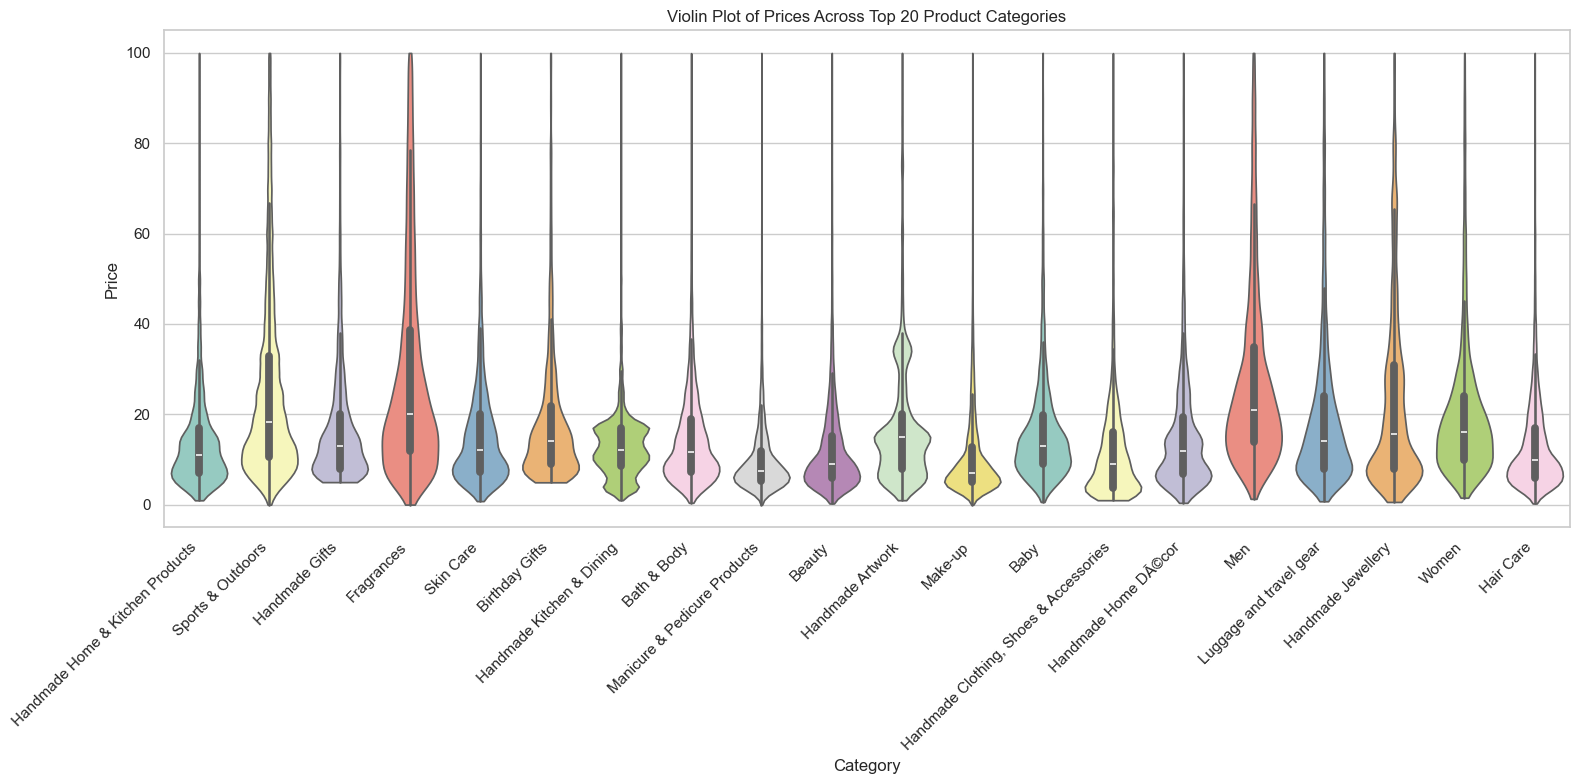

In [16]:
# 1. Violin Plots:

# Top 20 categorías con mayor número de productos
top20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

top20_categories

# Violin plot of prices across top 20 categories
plt.figure(figsize=(16,8))

sns.violinplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top20_categories)],
    x='category',
    y='price',
    palette='Set3',
    cut=0
)

plt.title("Violin Plot of Prices Across Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [17]:
#category with highest median price (no top filter)

median_prices = df_no_outliers.groupby('category')['price'].median()
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print("Category with highest median price:", highest_median_category)
print("Median price:", highest_median_value)


Category with highest median price: Desktop PCs
Median price: 74.0


Top 10 categories: Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')
El average price del top10 es: category
Sports & Outdoors                         25.17
Birthday Gifts                            18.60
Handmade Gifts                            17.40
Skin Care                                 15.65
Bath & Body                               14.68
Hair Care                                 13.46
Handmade Clothing, Shoes & Accessories    12.96
Beauty                                    12.52
Make-up                                   10.61
Manicure & Pedicure Products              10.23
Name: price, dtype: float64


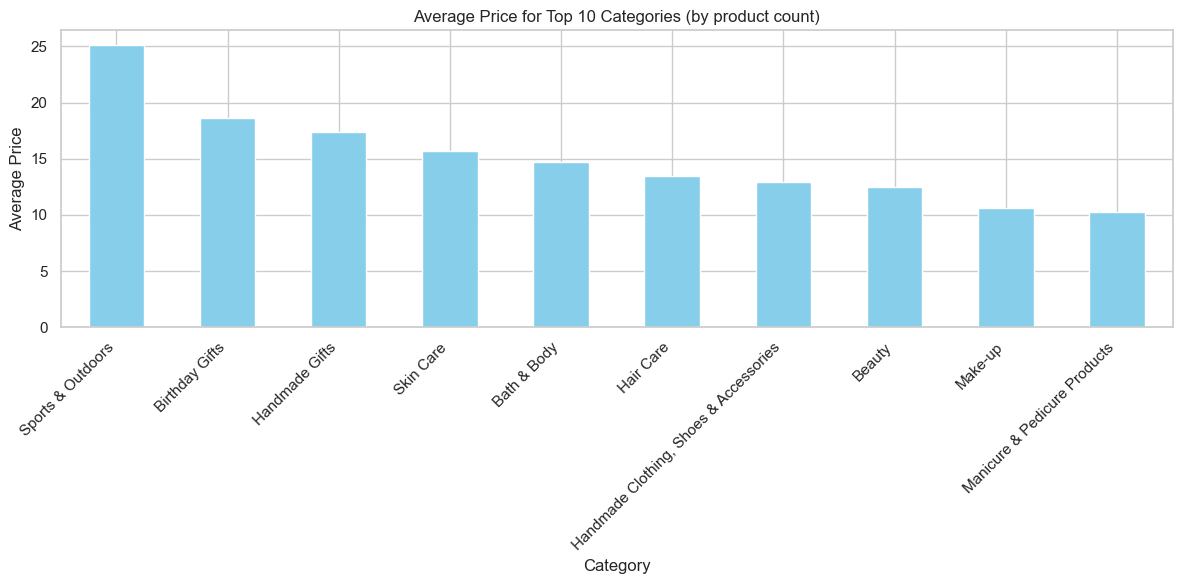

In [18]:
# 2. Bar Charts

# Top 10 categorías con mayor número de productos
top10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

print(f'Top 10 categories:', top10_categories)

# Average price for top 10 categories
avg_price_top10 = (
    df_no_outliers[df_no_outliers['category'].isin(top10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

print(f'El average price del top10 es:', round(avg_price_top10, 2))

#bar chart average price top 10 categories
plt.figure(figsize=(12,6))
avg_price_top10.plot(kind='bar', color='skyblue')

plt.title("Average Price for Top 10 Categories (by product count)")
plt.ylabel("Average Price")
plt.xlabel("Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [19]:
#category with highest average price (no top filter)

avg_prices_all = df_no_outliers.groupby('category')['price'].mean()

highest_avg_category = avg_prices_all.idxmax()
highest_avg_value = avg_prices_all.max()

print("Category with highest average price:", highest_avg_category)
print("Average price:", round(highest_avg_value,2))


Category with highest average price: Motherboards
Average price: 68.77


C:\Users\marle\AppData\Local\Temp\ipykernel_10228\3021453269.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


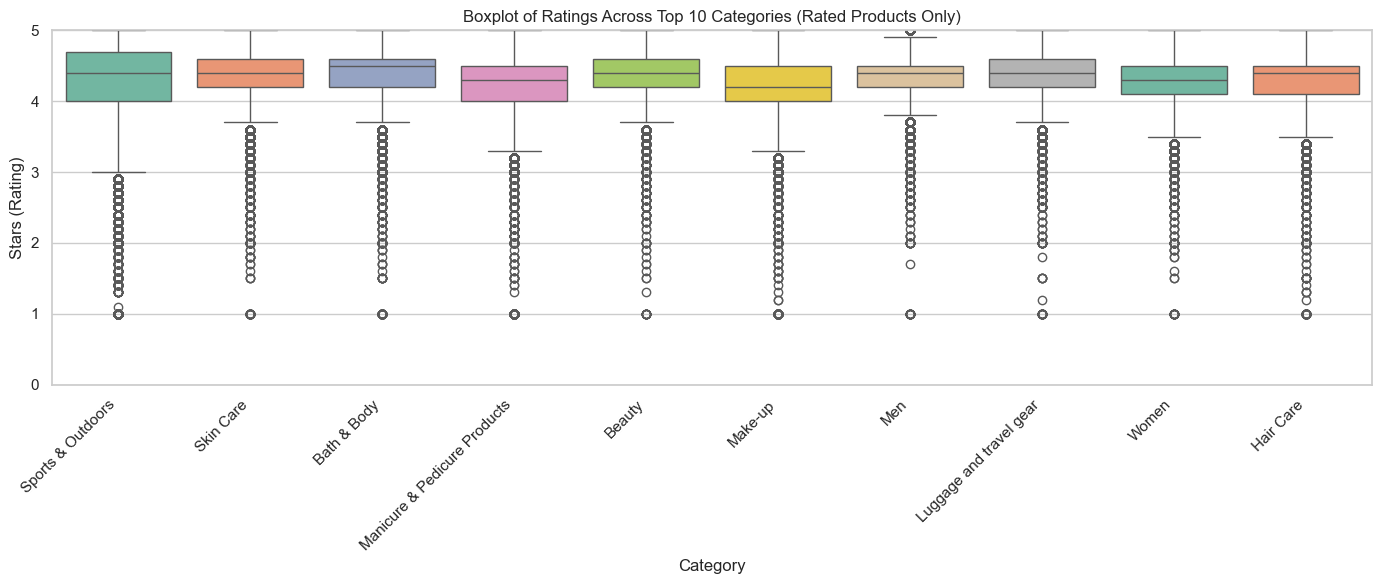

In [20]:
# 3. Box Plots

#filtering rated products (stars > 0)
df_rated = df_no_outliers[df_no_outliers['stars'] > 0]

#Getting top 10 categories by count
top10_categories_rated = (
    df_rated['category']
    .value_counts()
    .head(10)
    .index
)

top10_categories_rated

#Box plot of ratings across top 10 categories (rated products only)

plt.figure(figsize=(14,6))

sns.boxplot(
    data=df_rated[df_rated['category'].isin(top10_categories_rated)], 
    x='category', 
    y='stars',
    palette='Set2'
)

plt.title("Boxplot of Ratings Across Top 10 Categories (Rated Products Only)")
plt.xlabel("Category")
plt.ylabel("Stars (Rating)")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
#category with highest median rating (no top filter)

median_ratings = df_rated.groupby('category')['stars'].median()
median_ratings.head()

highest_median_category = median_ratings.idxmax()
highest_median_value = median_ratings.max()

print("Category with highest median rating:", highest_median_category)
print("Median rating:", highest_median_value)


Category with highest median rating: Handmade Artwork
Median rating: 5.0


In [22]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (`stars`) correlate with product prices.

# 1) Correlation Coefficients:
#    - Calculate the correlation coefficient between `price` and `stars`.
#    - Is there a significant correlation between product price and its rating?

# 2) Visualizations:
#    - Scatter plot: `stars` vs `price` to observe patterns.
#    - Correlation heatmap: visualize correlations among numerical variables.
#    - QQ plot: examine if product prices follow a normal distribution.

In [23]:
# 1. Correlation Coefficients

correlation, p_value = pearsonr(df_no_outliers['price'], df_no_outliers['stars'])
print("Correlation coefficient between price and stars:", round(correlation,2))


Correlation coefficient between price and stars: -0.08


In [24]:
# The Pearson correlation coefficient is −0.08, which is very close to zero.
# This indicates an extremely weak and negligible linear relationship between price and stars.
# In practical terms, higher-priced products are not rated better (or worse) than cheaper ones in any meaningful way.

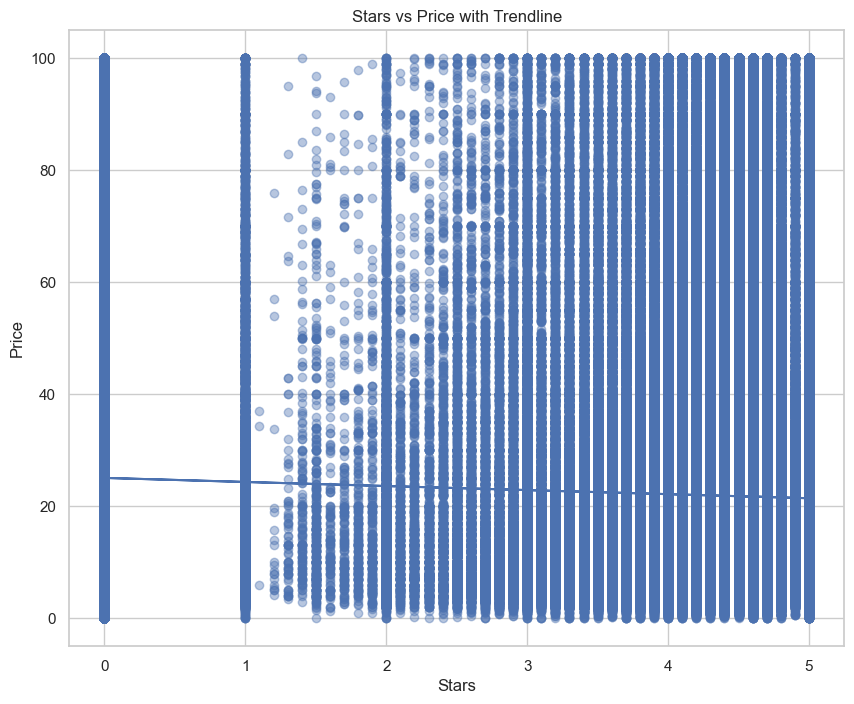

In [29]:
# 2) Visualizations:

#Scatter plot: `stars` vs `price` to observe patterns.

y = df_no_outliers['price']
x = df_no_outliers['stars']

# Linear trendline
m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(10, 8))
plt.scatter(x, y, alpha=0.4)
plt.plot(x, m*x + b)
plt.xlabel('Stars')
plt.ylabel('Price')
plt.title('Stars vs Price with Trendline')
plt.show()

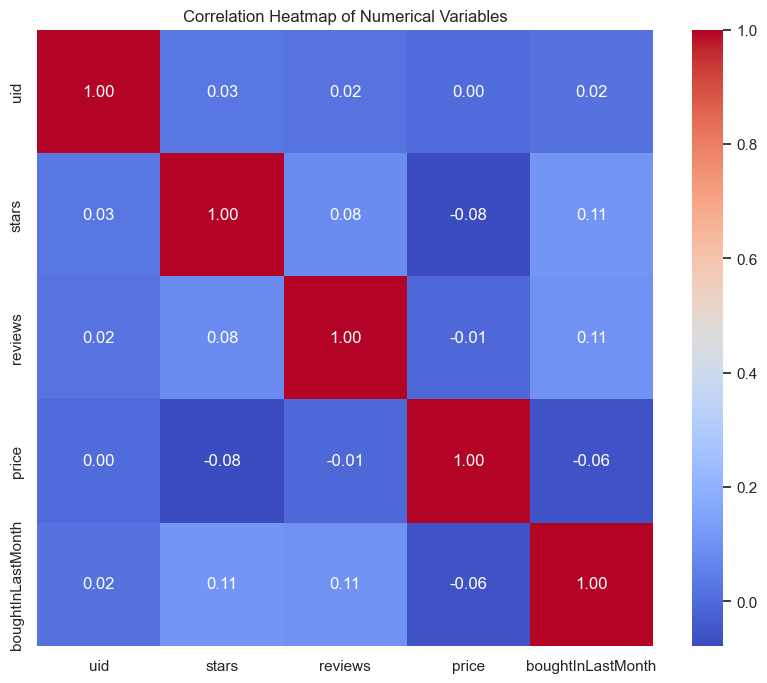

In [30]:
#Correlation heatmap: visualize correlations among numerical variables.

numerical_cols = df_no_outliers.select_dtypes(include=[np.number])
corr_matrix = numerical_cols.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Correlation Heatmap of Numerical Variables") 
plt.show()


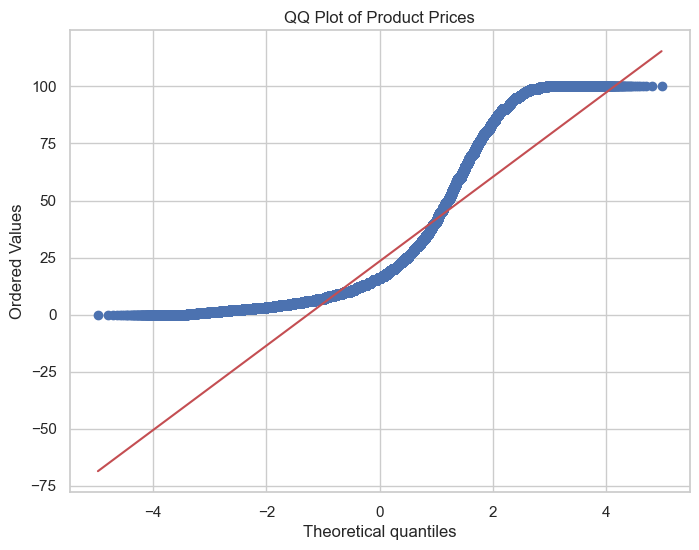

In [31]:
#QQ plot: examine if product prices follow a normal distribution.

plt.figure(figsize=(8, 6))
probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

